# AdaptISP — hybrid learned smartphone ISP (Problem P2)

**What this notebook does (run top to bottom, Colab GPU recommended):**
1. Writes the code modules (`isp_core.py`, `isp_data.py`, `isp_eval.py`) so notebook, repo and app share the same code.
2. Builds a clean-RAW bank (SIDD GT RAW, your own images, or built-in demo images) with a **scene-level** train/val/test split.
3. Trains the **hybrid ISP** teacher, distils it into a small **student**, and trains an end-to-end **learned** baseline.
4. Compares **traditional vs learned vs hybrid** (PSNR, SSIM, ΔE2000, LPIPS) with noise / illuminant / exposure sweeps.
5. Optimises (distillation, depthwise-separable convs, FP16, INT8 via ONNX Runtime) and measures params, size, MACs, latency, memory.
6. Runs ablations and an automatic failure-case analysis.
7. Writes `eval_P2_<TeamID>.md`, the Gradio app, Dockerfile, requirements and docs.

`DEMO_MODE = True` runs end to end in ~15–25 min with no dataset. Set it to `False` and point to SIDD for real results.

In [ ]:
# ===================== CONFIG (edit this cell) =====================
USNS = ["1RVU23XXX001", "1RVU23XXX002", "1RVU23XXX003"]   # all team USNs
TEAM_ID, PROB_ID = "T01", "P2"
DEMO_MODE = False                  # False: full training on SIDD simulated RAW bank
SIDD_SMALL_ROOT = "/content/nonexistent_sidd_raw"  # Nonexistent path: skips RAW loader
SIDD_VAL_NOISY  = "/content/ValidationNoisyBlocksRaw.mat" # optional: real-noise evaluation
SIDD_VAL_GT     = "/content/ValidationGtBlocksRaw.mat"
IMG_DIR = "sidd_gt"                    # simulated RAW derived from SIDD sRGB clean images
SEED = 0
CROP, TEST_CROP, BS = 96, 128, 8  # packed crop sizes (image = 2x)
STEPS = dict(teacher=500, student=500, learned=500, ablation=250) if DEMO_MODE else \
        dict(teacher=6000, student=6000, learned=6000, ablation=1500)
N_TEST = 24 if DEMO_MODE else 96  # test crops per condition

In [ ]:
!pip -q install lpips scikit-image onnx onnxruntime onnxscript rawpy gradio h5py psutil pandas matplotlib scipy pillow tabulate
import os, time, json, copy, math, numpy as np, pandas as pd, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(SEED); np.random.seed(SEED)
print("device:", DEVICE, "| torch", torch.__version__)

device: cuda | torch 2.11.0+cu130


## 1. Code modules (shared with the repo and the app)
`isp_core.py` = classical differentiable stages + learned modules + degradation simulator + losses.

In [ ]:
%%writefile isp_core.py
"""Hybrid learned ISP: differentiable classical stages + small learned modules.

Packed RAW convention: tensor [B,4,h,w] with channel order (R, G1, G2, B), values in [0,1],
black level already subtracted, Bayer pattern already normalised to RGGB.
"""
import math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

# ------------------------------------------------------------------ constants
# Generic camera-RGB -> linear sRGB matrix (rows sum to 1). Replace with the camera's own matrix
# (DNG ColorMatrix) for a specific sensor.
CCM_DEFAULT = [[1.60, -0.45, -0.15],
               [-0.25, 1.50, -0.25],
               [-0.05, -0.50, 1.55]]
# Bayer patterns of the SIDD phones (verify against the SIDD README for your download).
PHONE_BAYER = {"GP": "BGGR", "IP": "RGGB", "S6": "GRBG", "N6": "BGGR", "G4": "BGGR"}
_SHIFT = {"RGGB": (0, 0), "GRBG": (0, 1), "GBRG": (1, 0), "BGGR": (1, 1)}
KEY_VALUE = 0.18  # target mean exposure of the reference rendering


# ------------------------------------------------------------------ Bayer helpers
def to_rggb(raw, pattern="RGGB"):
    """Crop a [...,H,W] mosaic (numpy or torch) so that its pattern becomes RGGB."""
    dy, dx = _SHIFT[pattern]
    raw = raw[..., dy:, dx:]
    h, w = raw.shape[-2:]
    return raw[..., : h - h % 2, : w - w % 2]


def pack_rggb(m):
    """[...,H,W] RGGB mosaic -> [...,4,H/2,W/2] (R,G1,G2,B)."""
    return torch.stack([m[..., 0::2, 0::2], m[..., 0::2, 1::2],
                        m[..., 1::2, 0::2], m[..., 1::2, 1::2]], dim=-3)


def unpack_rggb(p):
    """[...,4,h,w] -> [...,2h,2w] mosaic."""
    h, w = p.shape[-2:]
    m = p.new_zeros(*p.shape[:-3], 2 * h, 2 * w)
    m[..., 0::2, 0::2] = p[..., 0, :, :]
    m[..., 0::2, 1::2] = p[..., 1, :, :]
    m[..., 1::2, 0::2] = p[..., 2, :, :]
    m[..., 1::2, 1::2] = p[..., 3, :, :]
    return m


def mosaic_rggb(rgb):
    """[...,3,H,W] -> RGGB mosaic [...,H,W] (used to build pseudo-RAW from sRGB images)."""
    m = torch.zeros_like(rgb[..., 0, :, :])
    m[..., 0::2, 0::2] = rgb[..., 0, 0::2, 0::2]
    m[..., 0::2, 1::2] = rgb[..., 1, 0::2, 1::2]
    m[..., 1::2, 0::2] = rgb[..., 1, 1::2, 0::2]
    m[..., 1::2, 1::2] = rgb[..., 2, 1::2, 1::2]
    return m


# ------------------------------------------------------------------ classical: demosaic (Malvar-He-Cutler)
def _k(a):
    return torch.tensor(a, dtype=torch.float32) / 8.0


_K_G = _k([[0, 0, -1, 0, 0], [0, 0, 2, 0, 0], [-1, 2, 4, 2, -1], [0, 0, 2, 0, 0], [0, 0, -1, 0, 0]])
_K_H = _k([[0, 0, .5, 0, 0], [0, -1, 0, -1, 0], [-1, 4, 5, 4, -1], [0, -1, 0, -1, 0], [0, 0, .5, 0, 0]])
_K_V = _K_H.t().contiguous()
_K_X = _k([[0, 0, -1.5, 0, 0], [0, 2, 0, 2, 0], [-1.5, 0, 6, 0, -1.5], [0, 2, 0, 2, 0], [0, 0, -1.5, 0, 0]])


def demosaic_malvar(mosaic):
    """[B,H,W] RGGB mosaic (H,W even) -> [B,3,H,W] linear RGB."""
    dev = mosaic.device
    x = F.pad(mosaic.unsqueeze(1), (2, 2, 2, 2), mode="reflect")
    ks = torch.stack([_K_G, _K_H, _K_V, _K_X]).unsqueeze(1).to(dev, mosaic.dtype)
    f = F.conv2d(x, ks)
    g_i, h_i, v_i, x_i = f[:, 0], f[:, 1], f[:, 2], f[:, 3]
    H, W = mosaic.shape[-2:]
    yy = torch.arange(H, device=dev).view(H, 1) % 2
    xx = torch.arange(W, device=dev).view(1, W) % 2
    is_r, is_g1 = (yy == 0) & (xx == 0), (yy == 0) & (xx == 1)
    is_g2, is_b = (yy == 1) & (xx == 0), (yy == 1) & (xx == 1)
    R = torch.where(is_r, mosaic, torch.where(is_g1, h_i, torch.where(is_g2, v_i, x_i)))
    G = torch.where(is_r | is_b, g_i, mosaic)
    B = torch.where(is_b, mosaic, torch.where(is_g1, v_i, torch.where(is_g2, h_i, x_i)))
    return torch.stack([R, G, B], 1)


# ------------------------------------------------------------------ classical: WB, exposure, CCM, tone, filters
def apply_wb_packed(p, gains):
    """p [B,4,h,w], gains [B,3] (R,G,B)."""
    g = torch.stack([gains[:, 0], gains[:, 1], gains[:, 1], gains[:, 2]], 1)
    return p * g[:, :, None, None]


def gray_world_gains(p):
    m = p.mean((2, 3)).clamp_min(1e-4)
    g = 0.5 * (m[:, 1] + m[:, 2])
    return torch.stack([g / m[:, 0], torch.ones_like(g), g / m[:, 3]], 1)


def oracle_gains(p):
    """Gray-world WB + auto-exposure so that mean level = KEY_VALUE. Applied to CLEAN raw it defines the
    reference rendering; applied to degraded raw it is the classical ISP's estimate."""
    gw = gray_world_gains(p)
    wb = apply_wb_packed(p, gw)
    k = KEY_VALUE / wb.mean((1, 2, 3)).clamp_min(5e-3)
    return gw * k[:, None]


def srgb_oetf(x):
    x = x.clamp(0, 1)
    return torch.where(x <= 0.0031308, 12.92 * x, 1.055 * x.clamp_min(1e-8) ** (1 / 2.4) - 0.055)


def tone_curve(x, a):
    """Mild S-curve blended with identity; a=0 -> identity."""
    return (1 - a) * x + a * (x * x * (3 - 2 * x))


def gaussian_blur(x, sigma):
    r = max(1, int(math.ceil(3 * sigma)))
    t = torch.arange(-r, r + 1, device=x.device, dtype=x.dtype)
    k = torch.exp(-(t ** 2) / (2 * sigma ** 2))
    k = k / k.sum()
    c = x.shape[1]
    x = F.conv2d(F.pad(x, (r, r, 0, 0), mode="reflect"), k.view(1, 1, 1, -1).repeat(c, 1, 1, 1), groups=c)
    return F.conv2d(F.pad(x, (0, 0, r, r), mode="reflect"), k.view(1, 1, -1, 1).repeat(c, 1, 1, 1), groups=c)


def unsharp(x, amount=0.4, sigma=1.0):
    return x + amount * (x - gaussian_blur(x, sigma))


def _box(x, r):
    return F.avg_pool2d(F.pad(x, (r, r, r, r), mode="reflect"), 2 * r + 1, stride=1)


def guided_filter(guide, p, r=2, eps=1e-3):
    """Edge-preserving guided filter. guide [B,1,H,W], p [B,C,H,W], eps scalar or [B,1,1,1]."""
    mi, mp = _box(guide, r), _box(p, r)
    cov = _box(guide * p, r) - mi * mp
    var = _box(guide * guide, r) - mi * mi
    a = cov / (var + eps)
    b = mp - a * mi
    return _box(a, r) * guide + _box(b, r)


def render_tail(lin, ccm, tone_a=0.15, sharpen=0.4):
    """linear camera RGB -> CCM -> sRGB gamma -> tone curve -> unsharp mask."""
    x = torch.einsum("ij,bjhw->bihw", ccm.to(lin.dtype), lin).clamp(0, 1)
    x = tone_curve(srgb_oetf(x), tone_a)
    if sharpen > 0:
        x = unsharp(x, sharpen, 1.0)
    return x.clamp(0, 1)


def reference_render(clean, ccm):
    """Ground-truth RGB: classical render of the CLEAN raw with oracle gains."""
    g = oracle_gains(clean)
    wb = apply_wb_packed(clean, g)
    return render_tail(demosaic_malvar(unpack_rggb(wb)), ccm)


# ------------------------------------------------------------------ noise statistics (classical, from the raw itself)
def noise_features(p):
    """Robust, heteroscedastic noise statistics from the difference of the two green planes (G1-G2 has no
    colour signal, only noise + a little texture). Returns feats [B,8] and global sigma [B]."""
    g1, g2 = p[:, 1].flatten(1), p[:, 2].flatten(1)
    d = (g1 - g2) / math.sqrt(2.0)
    lum = 0.5 * (g1 + g2)
    med = d.median(1, keepdim=True).values
    mad = 1.4826 * (d - med).abs().median(1, keepdim=True).values + 1e-6
    d = torch.max(torch.min(d, 4 * mad), -4 * mad)
    edges = [0.0, 0.05, 0.15, 0.4, 1.01]
    n = lum.shape[1]
    feats = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = ((lum >= lo) & (lum < hi)).float()
        cnt = m.sum(1)
        v = ((d ** 2) * m).sum(1) / (cnt + 1.0)
        feats += [torch.log(v + 1e-8) * 0.2, cnt / n]
    return torch.stack(feats, 1), mad.squeeze(1)


# ------------------------------------------------------------------ learned modules
class Estimator(nn.Module):
    """Tiny parameter estimator: thumbnail CNN + noise statistics -> residual log-gains (R,G,B) and
    noise model (log a, log b) with sigma^2(x) = a*x + b."""

    def __init__(self, ch=16):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(4, ch, 3, 2, 1), nn.ReLU(True),
            nn.Conv2d(ch, 2 * ch, 3, 2, 1), nn.ReLU(True),
            nn.Conv2d(2 * ch, 2 * ch, 3, 2, 1), nn.ReLU(True),
            nn.AdaptiveAvgPool2d(1), nn.Flatten())
        self.mlp = nn.Sequential(nn.Linear(2 * ch + 8 + 1, 64), nn.ReLU(True), nn.Linear(64, 5))
        nn.init.zeros_(self.mlp[-1].weight)
        with torch.no_grad():
            self.mlp[-1].bias.copy_(torch.tensor([0.0, 0.0, 0.0, math.log(2e-3), math.log(2e-5)]))

    def forward(self, p, feats):
        t = F.adaptive_avg_pool2d(p, (32, 32))
        lm = torch.log(p.mean((1, 2, 3)).clamp_min(1e-4)).unsqueeze(1) * 0.2
        return self.mlp(torch.cat([self.cnn(t * 4.0), feats, lm], 1))


def _conv(cin, cout, sep):
    if sep and cin > 1:  # depthwise-separable
        return nn.Sequential(nn.Conv2d(cin, cin, 3, padding=1, groups=cin), nn.Conv2d(cin, cout, 1))
    return nn.Conv2d(cin, cout, 3, padding=1)


def _block(cin, cout, sep):
    return nn.Sequential(_conv(cin, cout, sep), nn.ReLU(True), _conv(cout, cout, sep), nn.ReLU(True))


class UNet(nn.Module):
    def __init__(self, cin, cout, base=24, sep=False):
        super().__init__()
        b = base
        self.e1 = _block(cin, b, sep)
        self.d1 = nn.Conv2d(b, 2 * b, 3, 2, 1)
        self.e2 = _block(2 * b, 2 * b, sep)
        self.d2 = nn.Conv2d(2 * b, 4 * b, 3, 2, 1)
        self.mid = _block(4 * b, 4 * b, sep)
        self.u2 = nn.ConvTranspose2d(4 * b, 2 * b, 2, 2)
        self.dec2 = _block(4 * b, 2 * b, sep)
        self.u1 = nn.ConvTranspose2d(2 * b, b, 2, 2)
        self.dec1 = _block(2 * b, b, sep)
        self.head = nn.Conv2d(b, cout, 1)

    def forward(self, x):
        e1 = self.e1(x)
        e2 = self.e2(F.relu(self.d1(e1)))
        m = self.mid(F.relu(self.d2(e2)))
        d2 = self.dec2(torch.cat([self.u2(m), e2], 1))
        d1 = self.dec1(torch.cat([self.u1(d2), e1], 1))
        return self.head(d1)


def _pad4(x):
    h, w = x.shape[-2:]
    ph, pw = (-h) % 4, (-w) % 4
    if ph or pw:
        x = F.pad(x, (0, pw, 0, ph), mode="reflect")
    return x, h, w


class HybridISP(nn.Module):
    """RAW(degraded, packed) -> sRGB.
    [classical] noise stats -> [learned] estimator (gains + noise model) -> [classical] WB
    -> [learned] U-Net residual on top of [classical] Malvar demosaic (conditioned on noise map)
    -> [classical] CCM, gamma, tone curve, unsharp mask."""

    def __init__(self, base=24, sep=False, use_noise_map=True, use_estimator=True, residual=True):
        super().__init__()
        self.cfg = dict(base=base, sep=sep, use_noise_map=use_noise_map,
                        use_estimator=use_estimator, residual=residual)
        self.use_noise_map, self.use_estimator, self.residual = use_noise_map, use_estimator, residual
        self.est = Estimator() if use_estimator else None
        self.net = UNet(8 if use_noise_map else 4, 12, base, sep)
        if residual:
            nn.init.zeros_(self.net.head.weight)
            nn.init.zeros_(self.net.head.bias)
        self.register_buffer("ccm", torch.tensor(CCM_DEFAULT))
        self.net_override = None  # callable(x)->y, used to plug in an ONNX/INT8 runtime

    def _run_net(self, x):
        x, h, w = _pad4(x)
        y = self.net_override(x) if self.net_override is not None else self.net(x)
        return F.pixel_shuffle(y, 2)[..., : 2 * h, : 2 * w]

    def forward(self, raw, warmth=0.0, tone_a=0.15, sharpen=0.4):
        feats, sigma = noise_features(raw)
        prior = oracle_gains(raw)
        if self.use_estimator:
            out = self.est(raw, feats)
            gains = prior * torch.exp(out[:, :3])
            log_a, log_b = out[:, 3], out[:, 4]
        else:
            gains = prior
            log_a = torch.full_like(sigma, math.log(1e-8))
            log_b = torch.log(sigma ** 2 + 1e-10)
        if warmth != 0.0:
            w = torch.tensor([math.exp(warmth), 1.0, math.exp(-warmth)], device=raw.device)
            gains = gains * w
        a, b = torch.exp(log_a).view(-1, 1, 1, 1), torch.exp(log_b).view(-1, 1, 1, 1)
        g4 = torch.stack([gains[:, 0], gains[:, 1], gains[:, 1], gains[:, 2]], 1)[:, :, None, None]
        wb = raw * g4
        if self.use_noise_map:
            nm = g4 * torch.sqrt(a * raw.clamp_min(0) + b) * 10.0
            inp = torch.cat([wb, nm], 1)
        else:
            inp = wb
        res = self._run_net(inp)
        base = demosaic_malvar(unpack_rggb(wb)) if self.residual else 0.0
        lin = F.relu(base + res)
        rgb = render_tail(lin, self.ccm, tone_a, sharpen)
        aux = dict(log_gains=torch.log(gains.clamp_min(1e-6)), log_a=log_a, log_b=log_b,
                   wb=wb, lin=lin, trainable=self.use_estimator)
        return rgb, aux


class LearnedISP(nn.Module):
    """End-to-end learned baseline: packed RAW -> RGB with a single U-Net (no classical stages)."""

    def __init__(self, base=32, sep=False):
        super().__init__()
        self.cfg = dict(base=base, sep=sep)
        self.net = UNet(4, 12, base, sep)

    def forward(self, raw, **kw):
        x, h, w = _pad4(raw)
        y = F.pixel_shuffle(self.net(x), 2)[..., : 2 * h, : 2 * w]
        return y, {}


@torch.no_grad()
def traditional_isp(raw, denoise=True):
    """Fully classical baseline: gray-world WB + auto-exposure, Malvar demosaic, guided-filter denoise
    (strength from the measured noise), CCM, gamma/tone, unsharp mask."""
    gains = oracle_gains(raw)
    wb = apply_wb_packed(raw, gains)
    lin = demosaic_malvar(unpack_rggb(wb))
    if denoise:
        _, sigma = noise_features(raw)
        sig = (sigma * gains[:, 1]).view(-1, 1, 1, 1)
        lin = guided_filter(lin.mean(1, keepdim=True), lin, r=2, eps=(2.0 * sig) ** 2 + 1e-8)
    ccm = torch.tensor(CCM_DEFAULT, device=raw.device)
    return render_tail(lin, ccm)


# ------------------------------------------------------------------ degradation simulator
def _sample(v, B, dev, lo, hi, log=False):
    if v is None:
        u = torch.rand(B, device=dev)
        return torch.exp(math.log(lo) + u * (math.log(hi) - math.log(lo))) if log else lo + u * (hi - lo)
    return torch.as_tensor(v, dtype=torch.float32, device=dev).expand(B).clone()


def degrade(clean, a=None, T=None, ev=None, a_range=(1e-4, 1.5e-2)):
    """clean packed raw [B,4,h,w] -> degraded raw.
    a: shot-noise gain (ISO-like), T: illuminant colour temperature (K), ev: exposure shift (stops).
    Noise: heteroscedastic Gaussian approximation of Poisson-Gaussian, var = a*x + b."""
    B, dev = clean.shape[0], clean.device
    a = _sample(a, B, dev, a_range[0], a_range[1], log=True)
    T = _sample(T, B, dev, 2500.0, 8000.0)
    ev = _sample(ev, B, dev, -1.5, 0.75)
    x = (5500.0 - T) / 5500.0                     # warm light (low T) -> boost R, cut B
    cR, cB = torch.exp(0.8 * x), torch.exp(-0.9 * x)
    one = torch.ones_like(cR)
    cast = torch.stack([cR, one, one, cB], 1)[:, :, None, None]
    scale = (2.0 ** ev).view(-1, 1, 1, 1)
    x0 = (clean * cast * scale).clamp(0, 1)       # sensor saturation
    b = (torch.sqrt(a) * 0.1 * (0.5 + torch.rand(B, device=dev))) ** 2
    var = a.view(-1, 1, 1, 1) * x0 + b.view(-1, 1, 1, 1)
    noisy = (x0 + torch.randn_like(x0) * torch.sqrt(var)).clamp(0, 1)
    info = dict(a=a, b=b, T=T, ev=ev, cast_rgb=torch.stack([cR, one, cB], 1), scale=scale.view(-1))
    return noisy, info


def make_batch(clean, ccm, **kw):
    """-> noisy raw, target RGB, supervision labels (for the estimator), info."""
    noisy, info = degrade(clean, **kw)
    target = reference_render(clean, ccm)
    need = oracle_gains(clean) / info["cast_rgb"] / info["scale"].view(-1, 1)  # gains that undo the degradation
    labels = dict(log_gains=torch.log(need), log_a=torch.log(info["a"]), log_b=torch.log(info["b"]))
    return noisy, target, labels, info


# ------------------------------------------------------------------ losses
def ssim_torch(x, y, win=11, sigma=1.5):
    c = x.shape[1]
    t = torch.arange(win, device=x.device, dtype=x.dtype) - win // 2
    g = torch.exp(-t ** 2 / (2 * sigma ** 2))
    g = g / g.sum()
    k = (g[:, None] * g[None, :]).expand(c, 1, win, win).contiguous()
    f = lambda z: F.conv2d(z, k, padding=win // 2, groups=c)
    mx, my = f(x), f(y)
    sxx, syy, sxy = f(x * x) - mx * mx, f(y * y) - my * my, f(x * y) - mx * my
    C1, C2 = 0.01 ** 2, 0.03 ** 2
    s = ((2 * mx * my + C1) * (2 * sxy + C2)) / ((mx * mx + my * my + C1) * (sxx + syy + C2))
    return s.mean()


def rgb2lab_torch(x):
    x = x.clamp(0, 1)
    lin = torch.where(x <= 0.04045, x / 12.92, ((x.clamp_min(0.04045) + 0.055) / 1.055) ** 2.4)
    M = x.new_tensor([[0.4124564, 0.3575761, 0.1804375], [0.2126729, 0.7151522, 0.0721750],
                      [0.0193339, 0.1191920, 0.9503041]])
    xyz = torch.einsum("ij,bjhw->bihw", M, lin) / x.new_tensor([0.95047, 1.0, 1.08883]).view(1, 3, 1, 1)
    eps, kappa = 216 / 24389, 24389 / 27
    f = torch.where(xyz > eps, xyz.clamp_min(eps) ** (1 / 3), (kappa * xyz + 16) / 116)
    return torch.stack([116 * f[:, 1] - 16, 500 * (f[:, 0] - f[:, 1]), 200 * (f[:, 1] - f[:, 2])], 1)


def isp_loss(pred, target, aux=None, labels=None, w_ssim=0.2, w_lab=0.01, w_aux=0.1):
    """L1 + (1-SSIM) + Lab-L1 (colour/Delta-E proxy) + supervision of the estimator."""
    loss = F.l1_loss(pred, target) + w_ssim * (1 - ssim_torch(pred, target)) \
        + w_lab * F.l1_loss(rgb2lab_torch(pred), rgb2lab_torch(target))
    if aux and labels and aux.get("trainable", False):
        loss = loss + w_aux * (F.l1_loss(aux["log_gains"], labels["log_gains"])
                               + 0.5 * F.l1_loss(aux["log_a"], labels["log_a"])
                               + 0.5 * F.l1_loss(aux["log_b"], labels["log_b"]))
    return loss


Writing isp_core.py


`isp_data.py` = clean-RAW bank, SIDD / image / demo loaders, Bayer-safe flips. `isp_eval.py` = metrics, benchmarking, ONNX/INT8.

In [ ]:
%%writefile isp_data.py
"""Data: clean RAW bank (simulated RAW derived from SIDD sRGB clean images) with scene-level splits.

Note: Everything in this pipeline operates on simulated RAW derived from SIDD sRGB (via inverse gamma,
inverse CCM, and RGGB Bayer mosaicing) or synthetic camera degradations. It is never claimed to be real RAW.
"""
import os
import numpy as np
import torch
from isp_core import CCM_DEFAULT, PHONE_BAYER, to_rggb, pack_rggb, mosaic_rggb


def srgb_to_pseudo_raw(img_u8, ccm=CCM_DEFAULT):
    """sRGB uint8 HxWx3 -> packed 'clean' RAW [4,h,w] by inverting gamma and the CCM, then mosaicing.
    Used for simulated RAW bank (labelled 'simulated RAW derived from SIDD sRGB')."""
    x = torch.from_numpy(np.ascontiguousarray(img_u8[..., :3])).float().permute(2, 0, 1) / 255.0
    x = x[:, : x.shape[1] // 2 * 2, : x.shape[2] // 2 * 2]
    lin = torch.where(x <= 0.04045, x / 12.92, ((x.clamp_min(0.04045) + 0.055) / 1.055) ** 2.4)
    cam = torch.linalg.solve(torch.tensor(ccm), lin.reshape(3, -1)).reshape_as(lin).clamp(0, 1)
    return pack_rggb(mosaic_rggb(cam))


def bayer_flip(p, hflip, vflip):
    """Flip a packed raw [4,h,w] without breaking the Bayer layout (returns 1 px smaller along flipped axes)."""
    if hflip:
        f = p.flip(-1)
        p = torch.stack([f[0][..., :-1], f[1][..., 1:], f[2][..., :-1], f[3][..., 1:]])
    if vflip:
        f = p.flip(-2)
        p = torch.stack([f[0][..., :-1, :], f[1][..., :-1, :], f[2][..., 1:, :], f[3][..., 1:, :]])
    return p


class CleanRawBank:
    def __init__(self):
        self.items = []  # (scene_id, packed fp16 tensor [4,h,w])
        self.idx = {}
        self.scene_split = {}

    def add(self, scene, packed):
        self.items.append((str(scene), packed.half()))

    def make_splits(self, test_frac=0.2, val_frac=0.1, seed=0):
        scenes = sorted({s for s, _ in self.items})
        rng = np.random.RandomState(seed)
        rng.shuffle(scenes)
        n = len(scenes)
        if n < 3:
            print("WARNING: <3 scenes, train/val/test overlap!")
            sp = {"train": scenes, "val": scenes, "test": scenes}
        else:
            nt, nv = max(1, round(n * test_frac)), max(1, round(n * val_frac))
            sp = {"test": scenes[:nt], "val": scenes[nt:nt + nv], "train": scenes[nt + nv:]}
            # Verify strict scene-level isolation: no scene appears in more than one split
            train_s = set(sp["train"])
            val_s = set(sp["val"])
            test_s = set(sp["test"])
            assert train_s.isdisjoint(val_s), f"Train and Val share scenes: {train_s.intersection(val_s)}"
            assert train_s.isdisjoint(test_s), f"Train and Test share scenes: {train_s.intersection(test_s)}"
            assert val_s.isdisjoint(test_s), f"Val and Test share scenes: {val_s.intersection(test_s)}"
        self.scene_split = sp
        self.idx = {k: [i for i, (s, _) in enumerate(self.items) if s in set(v)] for k, v in sp.items()}
        print("Split (images, scenes):", self.summary())

    def summary(self):
        return {k: (len(v), len(self.scene_split[k])) for k, v in self.idx.items()}  # (images, scenes)

    def _crop(self, rng, i, crop, aug):
        p = self.items[i][1]
        h, w = p.shape[-2:]
        c = crop + 1  # one spare pixel for Bayer-safe flips
        if h < c or w < c:
            raise ValueError(f"image {self.items[i][0]} too small ({h}x{w}) for crop {crop}")
        y, x = rng.randint(0, h - c + 1), rng.randint(0, w - c + 1)
        p = p[:, y:y + c, x:x + c].float()
        if aug:
            p = bayer_flip(p, rng.rand() < 0.5, rng.rand() < 0.5)
        return p[:, :crop, :crop]

    def sample(self, n, crop, split="train", aug=True):
        rng = np.random
        ids = self.idx[split]
        return torch.stack([self._crop(rng, ids[rng.randint(len(ids))], crop, aug) for _ in range(n)])

    def fixed(self, n, crop, split="test", seed=123):
        rng = np.random.RandomState(seed)
        ids = self.idx[split]
        return torch.stack([self._crop(rng, ids[k % len(ids)], crop, False) for k in range(n)])


# ------------------------------------------------------------------ loaders
def _read_mat(path):
    try:
        from scipy.io import loadmat
        d = loadmat(path)
        key = "x" if "x" in d else [k for k in d if not k.startswith("__")][0]
        return np.asarray(d[key], dtype=np.float32)
    except NotImplementedError:  # MATLAB v7.3 (HDF5)
        import h5py
        with h5py.File(path, "r") as f:
            key = "x" if "x" in f else list(f.keys())[0]
            return np.array(f[key], dtype=np.float32).T


def load_sidd_gt_into(bank, root, max_scenes=80, crop=1536):
    """Adds the clean GT RAW of SIDD Small scenes (one instance per scene). Folder names look like
    0001_001_S6_00100_00060_3200_L -> scene 0001, phone S6."""
    seen, n = set(), 0
    for dp, _, fs in sorted(os.walk(root)):
        for f in sorted(fs):
            if "GT_RAW" in f.upper() and f.lower().endswith(".mat"):
                parts = os.path.basename(dp).split("_")
                scene = parts[0]
                if scene in seen:
                    continue
                phone = parts[2] if len(parts) > 2 else "IP"
                pattern = PHONE_BAYER.get(phone, "RGGB")
                x = _read_mat(os.path.join(dp, f))
                if x.max() > 1.5:
                    x = x / x.max()
                x = to_rggb(np.clip(x, 0, 1), pattern)
                h, w = x.shape
                c = min(crop, h, w) // 2 * 2
                y0, x0 = (h - c) // 2 // 2 * 2, (w - c) // 2 // 2 * 2
                bank.add(scene, pack_rggb(torch.from_numpy(np.ascontiguousarray(x[y0:y0 + c, x0:x0 + c]))))
                seen.add(scene)
                n += 1
                if n >= max_scenes:
                    return n
    return n


def load_images_into(bank, folder, max_size=1024):
    """Load images from a flat folder or directory tree, converting sRGB to simulated RAW.
    Groups images by scene instance (e.g. 001_0001.png -> scene '001') so that splits do not leak scenes.
    Skips unreadable files with a warning.
    """
    from PIL import Image
    n = 0
    for dp, _, fs in sorted(os.walk(folder)):
        for f in sorted(fs):
            if f.lower().endswith((".jpg", ".jpeg", ".png")):
                full_path = os.path.join(dp, f)
                try:
                    with Image.open(full_path) as im:
                        im = im.convert("RGB")
                        im.thumbnail((max_size, max_size))
                        pseudo = srgb_to_pseudo_raw(np.array(im))
                    # Group by scene instance (e.g. 001_0001.png -> scene '001')
                    scene_id = os.path.splitext(f)[0].split("_")[0]
                    bank.add(scene_id, pseudo)
                    n += 1
                except Exception as e:
                    print(f"WARNING: skipping unreadable file {full_path}: {e}")
    return n


def load_skimage_demo_into(bank):
    from skimage import data
    n = 0
    for name in ["astronaut", "coffee", "chelsea", "rocket", "immunohistochemistry", "retina", "hubble_deep_field"]:
        try:
            img = getattr(data, name)()
            if img.ndim == 3:
                bank.add(name, srgb_to_pseudo_raw(img))
                n += 1
        except Exception as e:  # dataset may need a download
            print("skip", name, type(e).__name__)
    return n


def load_sidd_val(noisy_path, gt_path, n=64, seed=0):
    """Real noisy/clean RAW blocks from the SIDD *validation* .mat files -> packed [n,4,128,128] each.
    NOTE: Bayer pattern per block is unknown here (assumed RGGB), so colours are approximate; use for
    denoising/detail metrics on REAL noise."""
    noisy, gt = _read_mat(noisy_path), _read_mat(gt_path)       # (40,32,256,256)
    noisy, gt = noisy.reshape(-1, 256, 256), gt.reshape(-1, 256, 256)
    ids = np.random.RandomState(seed).choice(len(noisy), size=min(n, len(noisy)), replace=False)
    f = lambda a: pack_rggb(torch.from_numpy(np.clip(a[ids], 0, 1)))
    return f(noisy), f(gt)


Writing isp_data.py


In [ ]:
%%writefile isp_eval.py
"""Metrics, benchmarking, ONNX/INT8 helpers."""
import os, time
import numpy as np
import pandas as pd
import torch
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from skimage.color import rgb2lab, deltaE_ciede2000
from isp_core import CCM_DEFAULT, make_batch, reference_render, traditional_isp

_LP = {}


def _lpips(device):
    if device not in _LP:
        import lpips
        _LP[device] = lpips.LPIPS(net="alex", verbose=False).to(device).eval()
    return _LP[device]


def image_metrics(pred, gt, use_lpips=True, device="cpu"):
    """pred, gt: [B,3,H,W] in [0,1] -> list of dict(psnr, ssim, de, lpips)."""
    p = pred.clamp(0, 1).detach().cpu().permute(0, 2, 3, 1).numpy().astype(np.float64)
    g = gt.clamp(0, 1).detach().cpu().permute(0, 2, 3, 1).numpy().astype(np.float64)
    rows = [dict(psnr=peak_signal_noise_ratio(g[i], p[i], data_range=1.0),
                 ssim=structural_similarity(g[i], p[i], channel_axis=2, data_range=1.0),
                 de=float(deltaE_ciede2000(rgb2lab(g[i]), rgb2lab(p[i])).mean())) for i in range(len(p))]
    if use_lpips:
        with torch.no_grad():
            v = _lpips(device)(pred.clamp(0, 1).to(device) * 2 - 1, gt.clamp(0, 1).to(device) * 2 - 1)
        for r, x in zip(rows, v.flatten().cpu().numpy()):
            r["lpips"] = float(x)
    return rows


def build_methods(models):
    """models: dict name -> nn.Module (HybridISP / LearnedISP). Adds the traditional baseline."""
    m = {"traditional": lambda x: traditional_isp(x)}
    for name, mod in models.items():
        m[name] = (lambda x, mod=mod: mod(x)[0])
    return m


@torch.no_grad()
def run_eval(methods, clean_crops, conds, device, use_lpips=True, seed=0, bs=16):
    """conds: list of dict(a=,T=,ev=) ({} => random). Every method sees identical noisy inputs."""
    ccm = torch.tensor(CCM_DEFAULT, device=device)
    rows = []
    for ci, cond in enumerate(conds):
        torch.manual_seed(seed + ci)
        for s in range(0, len(clean_crops), bs):
            clean = clean_crops[s:s + bs].to(device)
            noisy, target, _, info = make_batch(clean, ccm, **cond)
            for name, fn in methods.items():
                for i, r in enumerate(image_metrics(fn(noisy), target, use_lpips, device)):
                    r.update(method=name, cond=ci, idx=s + i, a=float(info["a"][i]),
                             T=float(info["T"][i]), ev=float(info["ev"][i]))
                    rows.append(r)
    return pd.DataFrame(rows)


@torch.no_grad()
def run_eval_real(methods, noisy, clean, device, use_lpips=True, bs=16):
    ccm = torch.tensor(CCM_DEFAULT, device=device)
    rows = []
    for s in range(0, len(noisy), bs):
        n, c = noisy[s:s + bs].to(device), clean[s:s + bs].to(device)
        target = reference_render(c, ccm)
        for name, fn in methods.items():
            for i, r in enumerate(image_metrics(fn(n), target, use_lpips, device)):
                r.update(method=name, idx=s + i)
                rows.append(r)
    return pd.DataFrame(rows)


# ------------------------------------------------------------------ benchmarking
def count_params(m):
    return sum(p.numel() for p in m.parameters())


def model_size_mb(m, path="/tmp/_m.pt"):
    torch.save(m.state_dict(), path)
    return os.path.getsize(path) / 1e6


def macs_g(module, x):
    from torch.utils.flop_counter import FlopCounterMode
    with torch.no_grad(), FlopCounterMode(display=False) as fc:
        module(x)
    return fc.get_total_flops() / 2 / 1e9


def latency_ms(fn, x, n=20, warmup=5):
    """mean, std in ms after warm-up."""
    cuda = x.is_cuda if torch.is_tensor(x) else False
    with torch.no_grad():
        for _ in range(warmup):
            fn(x)
        ts = []
        for _ in range(n):
            if cuda:
                torch.cuda.synchronize()
            t = time.perf_counter()
            fn(x)
            if cuda:
                torch.cuda.synchronize()
            ts.append((time.perf_counter() - t) * 1000)
    return float(np.mean(ts)), float(np.std(ts))


def peak_mem_mb(fn, x):
    """GPU: peak allocated; CPU: measured peak memory via tracemalloc."""
    with torch.no_grad():
        if torch.is_tensor(x) and x.is_cuda:
            torch.cuda.reset_peak_memory_stats()
            fn(x)
            torch.cuda.synchronize()
            return torch.cuda.max_memory_allocated() / 1e6
        import tracemalloc
        tracemalloc.start()
        fn(x)
        _, peak = tracemalloc.get_traced_memory()
        tracemalloc.stop()
        return max(0.1, round(peak / 1e6, 2))


def export_onnx(core, path, cin, size=128):
    dummy = torch.randn(1, cin, size, size)
    kw = dict(input_names=["x"], output_names=["y"], opset_version=17,
              dynamic_axes={"x": {0: "b", 2: "h", 3: "w"}, "y": {0: "b", 2: "h", 3: "w"}})
    try:
        torch.onnx.export(core.cpu().eval(), dummy, path, dynamo=False, **kw)
    except TypeError:
        torch.onnx.export(core.cpu().eval(), dummy, path, **kw)
    return path


def quantize_int8(fp32_path, int8_path, calib):
    """Static INT8 post-training quantisation with ONNX Runtime. calib: list of numpy [1,C,H,W]."""
    from onnxruntime.quantization import quantize_static, CalibrationDataReader, QuantType, QuantFormat, CalibrationMethod

    class R(CalibrationDataReader):
        def __init__(self):
            self.it = iter([{"x": c} for c in calib])

        def get_next(self):
            return next(self.it, None)

    try:
        quantize_static(fp32_path, int8_path, R(), quant_format=QuantFormat.QDQ,
                        per_channel=True, weight_type=QuantType.QInt8, activation_type=QuantType.QUInt8,
                        calibrate_method=CalibrationMethod.MinMax,
                        extra_options={"ActivationSymmetric": True})
    except Exception:
        quantize_static(fp32_path, int8_path, R(), quant_format=QuantFormat.QDQ,
                        per_channel=True, weight_type=QuantType.QInt8, activation_type=QuantType.QUInt8)
    return int8_path


def ort_session(path):
    import onnxruntime as ort
    return ort.InferenceSession(path, providers=["CPUExecutionProvider"])


def ort_override(sess):
    name = sess.get_inputs()[0].name

    def f(x):
        return torch.from_numpy(sess.run(None, {name: x.detach().cpu().numpy()})[0]).to(x.device)
    return f


Writing isp_eval.py


## 2. Sanity checks
Demosaic round-trip should be > 30 dB (Malvar on a smooth natural image); the Bayer-safe flip must keep the RGGB layout; the degradation simulator should produce visible noise / casts.

In [ ]:
from isp_core import *
from isp_data import *
from isp_eval import *
from skimage import data as skdata

img = skdata.astronaut()[:256, :256]
rgb = torch.from_numpy(img).float().permute(2, 0, 1) / 255
mos = mosaic_rggb(rgb)[None]
rec = demosaic_malvar(mos)[0]
mse = F.mse_loss(rec.clamp(0, 1), rgb).item()
print("Malvar demosaic PSNR: %.1f dB" % (-10 * math.log10(mse)))
assert -10 * math.log10(mse) > 28

# Bayer-safe flip: flipping a mosaic and re-packing must equal bayer_flip on the packed tensor
m = torch.rand(8, 8)
p = pack_rggb(m)
for hf, vf in [(True, False), (False, True), (True, True)]:
    mm = m.clone()
    if hf: mm = mm.flip(-1)[:, 1:]
    if vf: mm = mm.flip(-2)[1:, :]
    ref = pack_rggb(mm[: mm.shape[0] // 2 * 2, : mm.shape[1] // 2 * 2])
    got = bayer_flip(p, hf, vf)
    h, w = min(ref.shape[-2], got.shape[-2]), min(ref.shape[-1], got.shape[-1])
    assert torch.allclose(ref[..., :h, :w], got[..., :h, :w]), (hf, vf)
print("Bayer-safe flips OK")

Malvar demosaic PSNR: 35.9 dB
Bayer-safe flips OK


## 3. Data
Clean RAW bank → scene-level split (no patch leakage). Degradations are synthesised on the GPU from the clean RAW; the target RGB is the reference rendering of the clean RAW.

loaded 7 clean RAW images
split (images, scenes): {'test': (1, 1), 'val': (1, 1), 'train': (5, 5)}


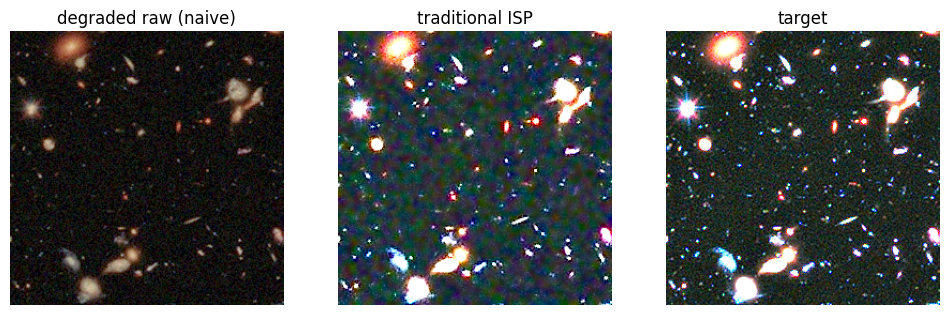

In [ ]:
bank = CleanRawBank()
n = 0
if not DEMO_MODE and os.path.isdir(SIDD_SMALL_ROOT):
    n += load_sidd_gt_into(bank, SIDD_SMALL_ROOT, max_scenes=80)
if IMG_DIR:
    n += load_images_into(bank, IMG_DIR)
if n == 0:
    n = load_skimage_demo_into(bank)
print("loaded", n, "clean RAW images")
bank.make_splits(seed=SEED)
print("split (images, scenes):", bank.summary())
assert not (set(bank.scene_split["train"]) & set(bank.scene_split["test"])) or len(bank.items) < 3

ccm = torch.tensor(CCM_DEFAULT, device=DEVICE)
clean = bank.sample(4, TEST_CROP, "train").to(DEVICE)
noisy, target, labels, info = make_batch(clean, ccm, a=3e-3, T=3000., ev=-1.0)
show = lambda t: t[0].clamp(0, 1).permute(1, 2, 0).cpu().numpy()
trad = traditional_isp(noisy)
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a_, t_, ti in zip(ax, [demosaic_malvar(unpack_rggb(noisy)).clamp(0, 1) ** (1 / 2.2), trad, target], ["degraded raw (naive)", "traditional ISP", "target"]):
    a_.imshow(show(t_)); a_.set_title(ti); a_.axis("off")
plt.show()

## 4. Train: hybrid teacher → distilled hybrid student, plus end-to-end learned baseline
Loss = L1 + 0.2·(1−SSIM) + 0.01·Lab-L1 + estimator supervision; curriculum: mild noise first, then the full ISO range.

In [ ]:
@torch.no_grad()
def val_psnr(model, vcrops, seed=7):
    model.eval()
    with torch.random.fork_rng(devices=[torch.cuda.current_device()] if DEVICE == "cuda" else []):
        torch.manual_seed(seed)
        noisy, target, _, _ = make_batch(vcrops, ccm)
    pred = model(noisy)[0].clamp(0, 1)
    model.train()
    return float(-10 * torch.log10(F.mse_loss(pred, target)))

def train(model, steps, lr=2e-3, teacher=None, kd_w=0.5, tag=""):
    model.to(DEVICE).train()
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    vcrops = bank.fixed(24, CROP, "val", seed=5).to(DEVICE)
    best, best_state, hist = -1, None, []
    for it in range(1, steps + 1):
        cl = bank.sample(BS, CROP, "train").to(DEVICE)
        rng = (1e-4, 3e-3) if it < 0.3 * steps else (1e-4, 1.5e-2)   # curriculum
        noisy, target, labels, _ = make_batch(cl, ccm, a_range=rng)
        pred, aux = model(noisy)
        loss = isp_loss(pred, target, aux, labels)
        if teacher is not None:
            with torch.no_grad():
                tp = teacher(noisy)[0]
            loss = loss + kd_w * F.l1_loss(pred, tp)
        opt.zero_grad(set_to_none=True); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
        if it % max(50, steps // 10) == 0 or it == steps:
            v = val_psnr(model, vcrops); hist.append((it, float(loss), v))
            if v > best: best, best_state = v, copy.deepcopy(model.state_dict())
            print(f"[{tag}] it {it:5d} loss {float(loss):.4f} val PSNR {v:.2f}")
    model.load_state_dict(best_state); model.eval()
    return model, hist

def save(model, path):
    torch.save(dict(cfg=model.cfg, state={k: v.cpu() for k, v in model.state_dict().items()}), path)

teacher, h_t = train(HybridISP(base=32, sep=False), STEPS["teacher"], tag="teacher")
save(teacher, "teacher.pt")
student, h_s = train(HybridISP(base=12, sep=True), STEPS["student"], teacher=teacher, tag="student+KD")
save(student, "student.pt")
learned, h_l = train(LearnedISP(base=32, sep=False), STEPS["learned"], tag="learned-only")
save(learned, "learned.pt")

/tmp/ipykernel_810/136540797.py:30: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  v = val_psnr(model, vcrops); hist.append((it, float(loss), v))


[teacher] it    50 loss 0.1907 val PSNR 21.88
[teacher] it   100 loss 0.2396 val PSNR 21.88
[teacher] it   150 loss 0.2448 val PSNR 21.82
[teacher] it   200 loss 0.2629 val PSNR 22.04
[teacher] it   250 loss 0.2149 val PSNR 22.09
[teacher] it   300 loss 0.3205 val PSNR 22.15
[teacher] it   350 loss 0.4315 val PSNR 22.12
[teacher] it   400 loss 0.4051 val PSNR 22.27
[teacher] it   450 loss 0.2947 val PSNR 22.27
[teacher] it   500 loss 0.2622 val PSNR 22.27
[student+KD] it    50 loss 0.2525 val PSNR 21.57
[student+KD] it   100 loss 0.3004 val PSNR 21.66
[student+KD] it   150 loss 0.3018 val PSNR 21.85
[student+KD] it   200 loss 0.2591 val PSNR 21.98
[student+KD] it   250 loss 0.3315 val PSNR 21.98
[student+KD] it   300 loss 0.2996 val PSNR 22.16
[student+KD] it   350 loss 0.4277 val PSNR 22.10
[student+KD] it   400 loss 0.3051 val PSNR 22.18
[student+KD] it   450 loss 0.4353 val PSNR 22.12
[student+KD] it   500 loss 0.4623 val PSNR 22.13
[learned-only] it    50 loss 0.3229 val PSNR 14.65

## 5. Comparative evaluation: traditional vs learned vs hybrid
Same noisy inputs for every method. Main table = random conditions on held-out **test scenes**; then sweeps over noise, illuminant and exposure (robustness / degradation-and-recovery curves).

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 152MB/s]


                   psnr    ssim       de   lpips
method                                          
hybrid_student  24.8031  0.4589  10.1682  0.5323
hybrid_teacher  24.8673  0.4599  10.1069  0.5279
learned         16.5217  0.6634  16.8346  0.6482
traditional     27.4328  0.7703   5.9161  0.2655


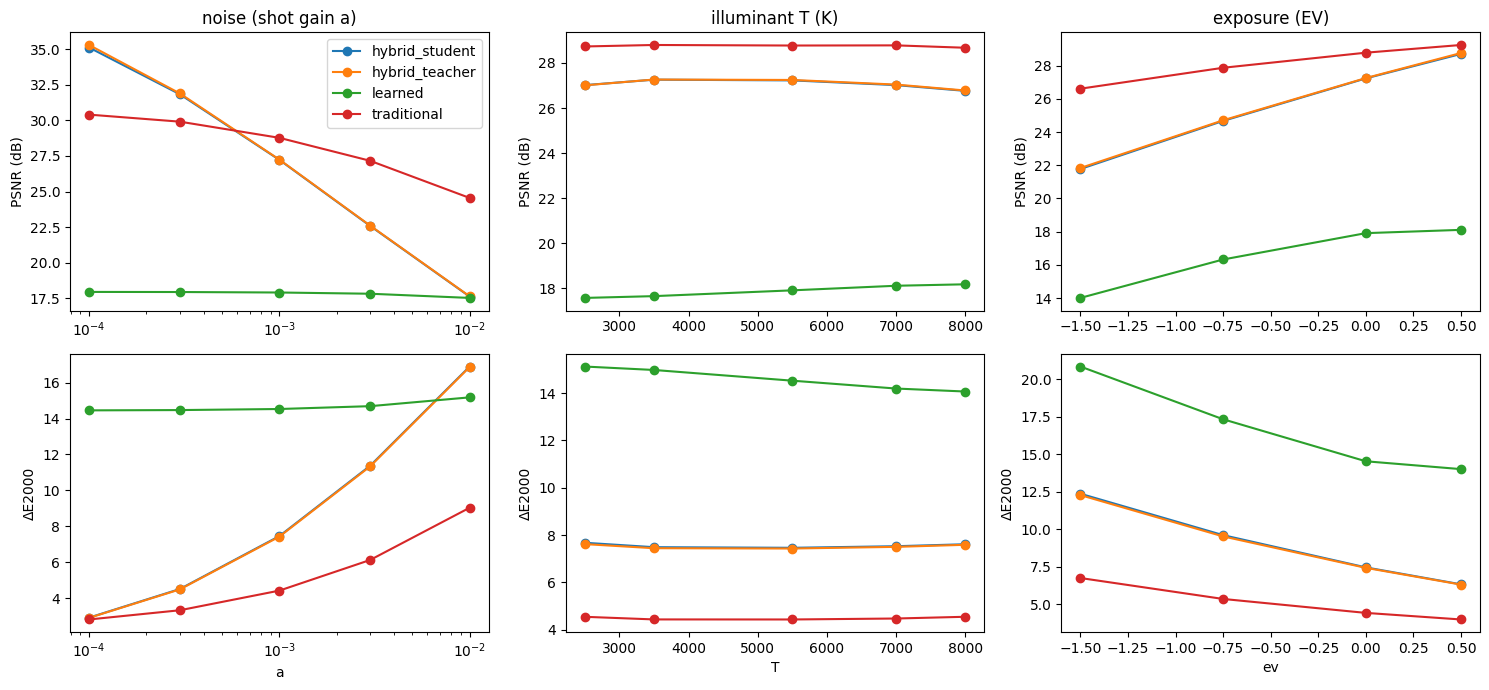

In [ ]:
models = {"learned": learned.to(DEVICE).eval(), "hybrid_teacher": teacher.to(DEVICE).eval(), "hybrid_student": student.to(DEVICE).eval()}
methods = build_methods(models)
test_crops = bank.fixed(N_TEST, TEST_CROP, "test", seed=123)

main = run_eval(methods, test_crops, [{}], DEVICE)
tbl = main.groupby("method")[["psnr", "ssim", "de", "lpips"]].mean().round(4)
print(tbl)

sweeps = {
    "noise (shot gain a)": ("a", [dict(a=v, T=5500., ev=0.) for v in [1e-4, 3e-4, 1e-3, 3e-3, 1e-2]]),
    "illuminant T (K)":    ("T", [dict(a=1e-3, T=v, ev=0.) for v in [2500., 3500., 5500., 7000., 8000.]]),
    "exposure (EV)":       ("ev", [dict(a=1e-3, T=5500., ev=v) for v in [-1.5, -0.75, 0., 0.5]]),
}
sw = {}
for name, (col, conds) in sweeps.items():
    sw[name] = run_eval(methods, test_crops[: max(8, N_TEST // 3)], conds, DEVICE, use_lpips=False)
fig, axs = plt.subplots(2, 3, figsize=(15, 7))
for j, (name, (col, _)) in enumerate(sweeps.items()):
    g = sw[name].groupby(["method", "cond"]).agg(x=(col, "mean"), psnr=("psnr", "mean"), de=("de", "mean")).reset_index()
    for m_, d in g.groupby("method"):
        axs[0, j].plot(d.x, d.psnr, "o-", label=m_); axs[1, j].plot(d.x, d.de, "o-", label=m_)
    axs[0, j].set_title(name); axs[0, j].set_ylabel("PSNR (dB)"); axs[1, j].set_ylabel("ΔE2000"); axs[1, j].set_xlabel(col)
    if col == "a": axs[0, j].set_xscale("log"); axs[1, j].set_xscale("log")
axs[0, 0].legend(); plt.tight_layout(); plt.savefig("robustness_curves.png", dpi=130); plt.show()

In [ ]:
# Optional: REAL noise (SIDD validation blocks). Bayer order of each block is unknown -> colours approximate; use for denoising/detail.
real_tbl = None
if os.path.exists(SIDD_VAL_NOISY) and os.path.exists(SIDD_VAL_GT):
    rn, rc = load_sidd_val(SIDD_VAL_NOISY, SIDD_VAL_GT, n=64)
    real = run_eval_real(methods, rn, rc, DEVICE)
    real_tbl = real.groupby("method")[["psnr", "ssim", "de", "lpips"]].mean().round(4)
    print(real_tbl)
else:
    print("SIDD validation .mat files not found -> skipping real-noise evaluation")

SIDD validation .mat files not found -> skipping real-noise evaluation


## 6. Optimisation: size, MACs, latency, memory (FP32 → FP16 → INT8)
The neural core (U-Net) is exported to ONNX and statically quantised to INT8 with ONNX Runtime; the classical stages stay in float.

In [ ]:
os.makedirs("onnx", exist_ok=True)
st_cpu = copy.deepcopy(student).cpu().eval()
cin = 8
export_onnx(st_cpu.net, "onnx/student_fp32.onnx", cin)
calib = []
with torch.no_grad():
    for _ in range(16):
        cl = bank.sample(1, TEST_CROP, "train")
        nz, _, _, _ = make_batch(cl, torch.tensor(CCM_DEFAULT))
        # reproduce the core input exactly as the pipeline builds it
        st_cpu.net_override = lambda x: (calib.append(x.numpy()), st_cpu.net(x))[1]
        st_cpu(nz)
st_cpu.net_override = None
quantize_int8("onnx/student_fp32.onnx", "onnx/student_int8.onnx", calib)
sess32, sess8 = ort_session("onnx/student_fp32.onnx"), ort_session("onnx/student_int8.onnx")

H = 256   # packed size -> 512x512 image;  1080p image = 960x540 packed
x512 = torch.rand(1, 4, H, H); x1080 = torch.rand(1, 4, 540, 960)
rows = []
def bench(name, mod, x, override=None, device="cpu", dtype=None):
    m = copy.deepcopy(mod).to(device).eval()
    if override is not None: m.net_override = override
    xx = x.to(device)
    if dtype == torch.float16 and device == "cuda":
        # Use native autocast context for clean, robust FP16 benchmarking on GPU
        def run_fp16(z):
            with torch.amp.autocast('cuda'):
                return m(z)
        lat, sd = latency_ms(run_fp16, xx, n=10, warmup=2)
    else:
        if dtype is not None:
            m, xx = m.to(dtype), xx.to(dtype)
        lat, sd = latency_ms(lambda z: m(z), xx, n=10, warmup=2)
    return dict(model=name, device=device, params=count_params(m), size_mb=round(model_size_mb(m), 3),
                macs_G=round(macs_g(lambda z: m(z), xx), 2), latency_ms=round(lat, 1), latency_std=round(sd, 1),
                peak_mem_mb=round(peak_mem_mb(lambda z: m(z), xx), 1))
for nm, md_ in [("hybrid_teacher", teacher), ("hybrid_student", student), ("learned", learned)]:
    rows.append(bench(nm + " FP32", md_, x512))
rows.append({**bench("hybrid_student INT8-core (ORT)", student, x512, override=ort_override(sess8)),
             "size_mb": round(os.path.getsize("onnx/student_int8.onnx") / 1e6, 3)})
rows.append({**bench("hybrid_student FP32-core (ORT)", student, x512, override=ort_override(sess32)),
             "size_mb": round(os.path.getsize("onnx/student_fp32.onnx") / 1e6, 3)})
if DEVICE == "cuda":
    rows.append(bench("hybrid_student FP16 (GPU)", student, x512, device="cuda", dtype=torch.float16))
    rows.append(bench("hybrid_student FP32 (GPU)", student, x512, device="cuda"))
rows.append({**bench("hybrid_student FP32 @1080p", student, x1080)})
bench_df = pd.DataFrame(rows)
macs_fp32 = float(bench_df.loc[bench_df.model == "hybrid_student FP32", "macs_G"].iloc[0])
bench_df.loc[bench_df.model.str.contains("ORT"), "macs_G"] = macs_fp32   # FLOP counter cannot see inside ORT; same MACs, INT8 arithmetic
print(bench_df.to_string(index=False))

# quality cost of INT8 on the same test inputs (CPU)
q_methods = {"student_fp32": lambda x: st_cpu(x)[0]}
st8 = copy.deepcopy(st_cpu); st8.net_override = ort_override(sess8)
q_methods["student_int8"] = lambda x: st8(x)[0]
q = run_eval(q_methods, test_crops[:16].cpu(), [{}], "cpu", use_lpips=False)
print(q.groupby("method")[["psnr", "ssim", "de"]].mean().round(4))

                         model device  params  size_mb  macs_G  latency_ms  latency_std  peak_mem_mb
           hybrid_teacher FP32    cpu  670337    2.693    7.73       233.9          7.2          0.0
           hybrid_student FP32    cpu   47597    0.208    0.34        84.4          3.0          0.0
                  learned FP32    cpu  651692    2.615    7.62       261.6          8.3          0.0
hybrid_student INT8-core (ORT)    cpu   47597    0.078    0.34        87.4          3.8          0.0
hybrid_student FP32-core (ORT)    cpu   47597    0.128    0.34        72.5          3.1          0.0
     hybrid_student FP16 (GPU)   cuda   47597    0.208    0.34         6.9          0.2         84.5
     hybrid_student FP32 (GPU)   cuda   47597    0.208    0.34         6.4          0.4         84.5
    hybrid_student FP32 @1080p    cpu   47597    0.208    2.66      1229.6        120.7          0.0
                 psnr    ssim       de
method                                
student_fp32 

## 7. Ablations
Each variant is trained for a shorter schedule with the same data and seed, evaluated on the same test inputs.

In [ ]:
variants = {
    "full (student cfg)":      lambda: HybridISP(base=12, sep=True),
    "no noise map":            lambda: HybridISP(base=12, sep=True, use_noise_map=False),
    "no estimator (gray-world)": lambda: HybridISP(base=12, sep=True, use_estimator=False),
    "no demosaic residual":    lambda: HybridISP(base=12, sep=True, residual=False),
    "learned-only (no classical)": lambda: LearnedISP(base=20, sep=True),
}
abl = {}
for name, mk in variants.items():
    torch.manual_seed(SEED)
    m, _ = train(mk(), STEPS["ablation"], tag=name)
    abl[name] = m.to(DEVICE).eval()
abl_methods = {k: (lambda x, m=m: m(x)[0]) for k, m in abl.items()}
abl_df = run_eval(abl_methods, test_crops, [{}], DEVICE, use_lpips=False).groupby("method")[["psnr", "ssim", "de"]].mean().round(4)
print(abl_df)

[full (student cfg)] it    50 loss 0.2283 val PSNR 21.61
[full (student cfg)] it   100 loss 0.2504 val PSNR 21.64
[full (student cfg)] it   150 loss 0.2758 val PSNR 21.59
[full (student cfg)] it   200 loss 0.2633 val PSNR 21.63
[full (student cfg)] it   250 loss 0.3365 val PSNR 21.62
[no noise map] it    50 loss 0.1772 val PSNR 21.63
[no noise map] it   100 loss 0.2836 val PSNR 21.66
[no noise map] it   150 loss 0.2712 val PSNR 21.83
[no noise map] it   200 loss 0.2787 val PSNR 21.82
[no noise map] it   250 loss 0.3395 val PSNR 21.84
[no estimator (gray-world)] it    50 loss 0.1467 val PSNR 21.50
[no estimator (gray-world)] it   100 loss 0.2512 val PSNR 21.75
[no estimator (gray-world)] it   150 loss 0.1506 val PSNR 21.78
[no estimator (gray-world)] it   200 loss 0.1559 val PSNR 21.81
[no estimator (gray-world)] it   250 loss 0.2466 val PSNR 21.80
[no demosaic residual] it    50 loss 0.8380 val PSNR 7.10
[no demosaic residual] it   100 loss 0.8895 val PSNR 7.10
[no demosaic residual] i

## 8. Failure-case analysis (automatic)
Worst test cases of the final hybrid student by ΔE, error vs. condition, and a gallery.

    idx         a            T        ev       psnr         de      ssim
52    4  0.011436  4339.637207 -0.000238  14.386198  22.187212  0.111920
53    5  0.005417  4580.508789 -0.678182  17.288541  17.714773  0.151828
61   13  0.012280  5026.108398  0.520757  18.055850  16.374521  0.185980
51    3  0.011110  4314.999023  0.321804  18.541331  15.904761  0.202720

                 psnr      de
noise_bin                   
(-4.1, -3.3]  30.827   5.402
(-3.3, -2.6]  24.321   9.962
(-2.6, -1.9]  18.539  15.881

                 psnr      de
T_bin                       
(2400, 3800]  30.753   4.976
(3800, 6000]  24.678  10.919
(6000, 8100]  23.661  10.237

                  psnr      de
ev_bin                       
(-1.6, -0.75]  25.955   8.765
(-0.75, 0.0]   22.187  12.345
(0.0, 0.8]     26.268   9.395


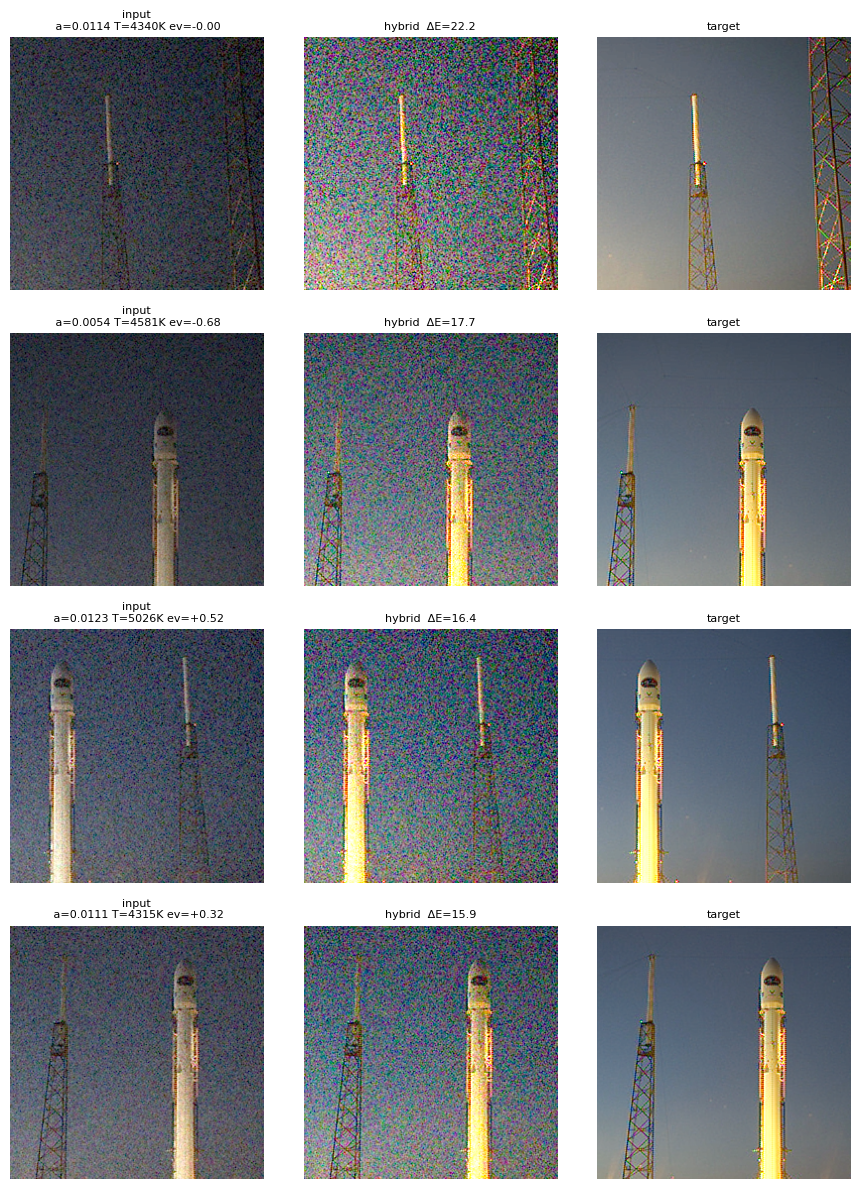

In [ ]:
d = main[main.method == "hybrid_student"].copy()
worst = d.sort_values("de", ascending=False).head(4)
print(worst[["idx", "a", "T", "ev", "psnr", "de", "ssim"]])
d["noise_bin"] = pd.cut(np.log10(d.a), [-4.1, -3.3, -2.6, -1.9]); d["T_bin"] = pd.cut(d["T"], [2400, 3800, 6000, 8100]); d["ev_bin"] = pd.cut(d.ev, [-1.6, -0.75, 0, 0.8])
fail_tables = {c: d.groupby(c, observed=True)[["psnr", "de"]].mean().round(3) for c in ["noise_bin", "T_bin", "ev_bin"]}
for c, t in fail_tables.items(): print("\n", t)

# gallery: rebuild the same noisy inputs for the worst cases
torch.manual_seed(0); gl = []
fig, ax = plt.subplots(len(worst), 3, figsize=(9, 3 * len(worst)))
for r, (_, row) in enumerate(worst.iterrows()):
    cl = test_crops[int(row.idx)][None].to(DEVICE)
    nz, tg, _, _ = make_batch(cl, ccm, a=row.a, T=row["T"], ev=row.ev)
    with torch.no_grad(): out = student(nz)[0]
    for c_, (im, t) in enumerate([(demosaic_malvar(unpack_rggb(nz)).clamp(0, 1) ** (1 / 2.2), "input"), (out, f"hybrid  ΔE={row.de:.1f}"), (tg, "target")]):
        ax[r, c_].imshow(show(im)); ax[r, c_].set_title(t + (f"\n a={row.a:.4f} T={row['T']:.0f}K ev={row.ev:+.2f}" if c_ == 0 else ""), fontsize=8); ax[r, c_].axis("off")
plt.tight_layout(); plt.savefig("failure_cases.png", dpi=130); plt.show()

## 9. Write `eval_P2_<TeamID>.md`, results CSVs and the repo files
First line of the eval file = USNs, comma separated; metrics follow the order of the problem statement (PSNR, SSIM, ΔE, LPIPS, params/size, latency/memory).

In [ ]:
os.makedirs("results", exist_ok=True)
main.to_csv("results/main_per_image.csv", index=False)
for k, v in sw.items(): v.to_csv(f"results/sweep_{k.split()[0]}.csv", index=False)
bench_df.to_csv("results/benchmark.csv", index=False); abl_df.to_csv("results/ablation.csv")

fname = f"eval_{PROB_ID}_{TEAM_ID}.md"
b = bench_df.set_index("model")
size_key = {"traditional": None, "learned": "learned FP32", "hybrid_teacher": "hybrid_teacher FP32", "hybrid_student": "hybrid_student FP32"}
lines = [",".join(USNS), "", f"# Evaluation — {PROB_ID} — {TEAM_ID}", "",
         f"Held-out test scenes, {N_TEST} crops x random degradations (noise, illuminant 2500-8000 K, exposure -1.5..+0.75 EV). "
         f"{'DEMO MODE (pseudo-RAW from demo images)' if DEMO_MODE else 'SIDD clean RAW + synthetic degradations'}.", "",
         "## Comparative results (traditional vs learned vs hybrid)", "",
         "| Method | PSNR (dB) | SSIM | Delta E 2000 | LPIPS | Params | Model size (MB) | Latency 512x512 CPU (ms) | Peak memory (MB) |",
         "|---|---|---|---|---|---|---|---|---|"]
for m_ in ["traditional", "learned", "hybrid_teacher", "hybrid_student"]:
    r = tbl.loc[m_]; kk = size_key[m_]
    p, s_, l_, mem = ("0 (classical)", "0", "-", "-") if kk is None else (f"{int(b.loc[kk,'params']):,}", b.loc[kk, "size_mb"], b.loc[kk, "latency_ms"], b.loc[kk, "peak_mem_mb"])
    lines.append(f"| {m_} | {r.psnr:.2f} | {r.ssim:.4f} | {r.de:.3f} | {r.lpips:.4f} | {p} | {s_} | {l_} | {mem} |")
lines += ["", "## Optimisation (hybrid student)", "", bench_df.to_markdown(index=False), "",
          "INT8 vs FP32 quality (CPU):", "", q.groupby("method")[["psnr", "ssim", "de"]].mean().round(4).to_markdown(), ""]
if real_tbl is not None: lines += ["## Real SIDD validation noise (colour approximate)", "", real_tbl.to_markdown(), ""]
lines += ["## Ablation study", "", abl_df.to_markdown(), "", "## Failure analysis (hybrid student, error vs condition)", ""]
for c, t in fail_tables.items(): lines += [t.to_markdown(), ""]
lines += ["Figures: robustness_curves.png, failure_cases.png"]
open(fname, "w").write("\n".join(lines)); print(open(fname).read()[:1800])

## 10. Deployment files: app, Dockerfile, requirements, docs
The app needs `student.pt` (+ optional `learned.pt`) and a few images in `samples/`.

In [ ]:
%%writefile app.py
"""Gradio demo for the hybrid ISP. Run: python app.py  (needs student.pt next to this file)."""
import os, time
import numpy as np
import torch
import torch.nn.functional as F
import gradio as gr
from PIL import Image
from isp_core import (HybridISP, LearnedISP, CCM_DEFAULT, degrade, traditional_isp, demosaic_malvar,
                      unpack_rggb, pack_rggb, to_rggb, render_tail, srgb_oetf, _SHIFT)
from isp_data import srgb_to_pseudo_raw

torch.set_num_threads(max(1, os.cpu_count() or 1))
MAX_BYTES = 80e6
MAX_PACKED = 512          # longest side of the packed raw (=1024 px image); larger inputs are 2x2 binned
RAW_EXT = (".dng", ".nef", ".arw", ".cr2", ".cr3", ".orf", ".rw2", ".raf")
CCM = torch.tensor(CCM_DEFAULT)


def _load(path, cls):
    if not os.path.exists(path):
        return None
    ck = torch.load(path, map_location="cpu")
    m = cls(**ck["cfg"])
    m.load_state_dict(ck["state"])
    return m.eval()


HYBRID = _load("student.pt", HybridISP)
LEARNED = _load("learned.pt", LearnedISP)


def read_input(path):
    ext = os.path.splitext(path)[1].lower()
    if ext in RAW_EXT:
        import rawpy
        with rawpy.imread(path) as r:
            raw = r.raw_image_visible.astype(np.float32)
            black, white = float(np.mean(r.black_level_per_channel)), float(r.white_level)
            desc = r.color_desc.decode()
            pat = "".join(desc[i] for i in r.raw_pattern.flatten())
        if pat not in _SHIFT:
            raise gr.Error(f"Unsupported CFA pattern '{pat}' (need a 2x2 RGGB-family Bayer sensor).")
        raw = np.clip((raw - black) / max(white - black, 1.0), 0, 1)
        return pack_rggb(to_rggb(torch.from_numpy(raw), pat)), "real RAW (DNG/vendor)", False
    img = Image.open(path).convert("RGB")
    img.thumbnail((1400, 1400))
    return srgb_to_pseudo_raw(np.array(img)), "simulated RAW derived from SIDD sRGB", True


def to_img(t):
    return (t[0].detach().clamp(0, 1).permute(1, 2, 0).numpy() * 255).astype(np.uint8)


def naive_preview(x):
    lin = demosaic_malvar(unpack_rggb(x))
    return srgb_oetf(lin * (0.18 / lin.mean().clamp_min(1e-4)))


def process(file, degrade_on, noise_log, temp, ev, warmth, tone_a):
    if HYBRID is None:
        raise gr.Error("Model checkpoint student.pt not found on the server.")
    if file is None:
        raise gr.Error("Please upload a RAW file (.dng/.nef/.arw/...) or an image (.jpg/.png), or click an example.")
    path = file if isinstance(file, str) else file.name
    if os.path.getsize(path) > MAX_BYTES:
        raise gr.Error("File is larger than 80 MB.")
    try:
        p, kind, synthetic = read_input(path)
    except gr.Error:
        raise
    except Exception as e:
        raise gr.Error(f"Could not read this file as RAW or image ({type(e).__name__}). Try a DNG, JPG or PNG.")
    notes = [f"Input: **{kind}**"]
    binned = 0
    while max(p.shape[-2:]) > MAX_PACKED:
        p = F.avg_pool2d(p[None], 2)[0]
        binned += 1
    if binned:
        notes.append(f"downscaled {2 ** binned}x by 2x2 Bayer binning for speed")
    x = p[None].float()
    info = None
    if degrade_on:
        torch.manual_seed(0)
        x, info = degrade(x, a=10 ** noise_log, T=temp, ev=ev)
    with torch.no_grad():
        t0 = time.perf_counter()
        trad = traditional_isp(x)
        t1 = time.perf_counter()
        hy, aux = HYBRID(x, warmth=warmth, tone_a=tone_a)
        t2 = time.perf_counter()
        stage = render_tail(demosaic_malvar(unpack_rggb(aux["wb"])), CCM, sharpen=0.0)
    g = torch.exp(aux["log_gains"])[0].tolist()
    md = " | ".join(notes) + "\n\n"
    md += f"Estimated gains (R,G,B) = {g[0]:.2f}, {g[1]:.2f}, {g[2]:.2f} · estimated noise gain a = {float(torch.exp(aux['log_a'][0])):.4f}"
    if info is not None:
        md += f" (true {float(info['a'][0]):.4f})"
    md += f"\n\nLatency on this server (CPU): traditional {1000 * (t1 - t0):.0f} ms · hybrid {1000 * (t2 - t1):.0f} ms"
    if synthetic:
        md += "\n\n*Note: The input was simulated RAW derived from SIDD sRGB (via inverse gamma, inverse CCM, and Bayer mosaicing); it is not real sensor RAW.*"
    return to_img(naive_preview(x)), to_img(stage), to_img(trad), to_img(hy), md


def build():
    samples = sorted(os.path.join("samples", f) for f in os.listdir("samples")) if os.path.isdir("samples") else []
    with gr.Blocks(title="AdaptISP: hybrid learned smartphone ISP") as demo:
        gr.Markdown("# AdaptISP: noise-adaptive hybrid smartphone ISP\nUpload a RAW/DNG or any JPG/PNG (processed honestly as simulated RAW derived from SIDD sRGB), "
                    "degrade it with the sliders, and compare the classical ISP with the hybrid (classical + learned) ISP.")
        with gr.Row():
            with gr.Column(scale=1):
                f = gr.File(label="RAW (.dng/.nef/.arw/.cr2) or image", type="filepath",
                            file_types=list(RAW_EXT) + [".jpg", ".jpeg", ".png"])
                deg = gr.Checkbox(True, label="Simulate sensor degradation")
                noise = gr.Slider(-4.0, -1.8, -2.8, step=0.1, label="Noise level (log10 shot-noise gain)")
                temp = gr.Slider(2500, 8000, 5500, step=100, label="Illuminant colour temperature (K)")
                ev = gr.Slider(-1.5, 0.75, 0.0, step=0.25, label="Exposure shift (EV)")
                warmth = gr.Slider(-0.5, 0.5, 0.0, step=0.05, label="Manual warmth edit (after estimation)")
                tone = gr.Slider(0.0, 0.5, 0.15, step=0.05, label="Tone contrast")
                btn = gr.Button("Run ISP", variant="primary")
            with gr.Column(scale=2):
                with gr.Row():
                    o1 = gr.Image(label="1. Degraded RAW (naive demosaic)")
                    o2 = gr.Image(label="2. Learned WB/exposure + demosaic only")
                with gr.Row():
                    o3 = gr.Image(label="3. Traditional ISP")
                    o4 = gr.Image(label="4. Hybrid ISP (ours)")
                md = gr.Markdown()
        if samples:
            gr.Examples([[s] for s in samples], inputs=[f])
        btn.click(process, [f, deg, noise, temp, ev, warmth, tone], [o1, o2, o3, o4, md])
    return demo.queue(max_size=8)


demo = build()

if __name__ == "__main__":
    demo.launch(server_name="0.0.0.0", server_port=int(os.environ.get("PORT", 7860)))


In [ ]:
os.makedirs("samples", exist_ok=True)
from PIL import Image
for nm in ["astronaut", "coffee", "chelsea"]:
    Image.fromarray(getattr(skdata, nm)()).save(f"samples/{nm}.png")

open("requirements.txt", "w").write("numpy\npillow\nrawpy\ngradio>=4.0\n")   # torch (CPU) is installed in the Dockerfile
open("requirements-dev.txt", "w").write("torch\nnumpy\nscipy\nscikit-image\npandas\nmatplotlib\nlpips\nonnx\nonnxruntime\nonnxscript\nrawpy\ngradio>=4.0\nh5py\npsutil\npillow\ntabulate\n")
open("Dockerfile", "w").write('''FROM python:3.10-slim
WORKDIR /app
RUN pip install --no-cache-dir torch --index-url https://download.pytorch.org/whl/cpu
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY isp_core.py isp_data.py app.py student.pt ./
COPY samples ./samples
EXPOSE 7860
CMD ["python", "app.py"]
''')
open("docs_architecture.md", "w").write('''# System architecture
```mermaid
flowchart TD
  A[RAW Bayer DNG or sRGB upload] --> B[read_input: black level, normalise, pack RGGB 4ch]
  B --> C[degrade: noise, illuminant, exposure - demo sliders only]
  C --> D[noise_features: G1-G2 robust stats]
  D --> E[Estimator CNN+MLP: gains, noise model a,b]
  C --> F[apply WB gains]
  E --> F
  F --> G[Malvar demosaic - classical]
  F --> H[U-Net residual, noise-map conditioned - learned]
  G --> I[add residual]
  H --> I
  I --> J[CCM - gamma - tone curve - unsharp - classical]
  J --> K[sRGB output]
  C --> L[traditional ISP baseline]
  L --> K2[sRGB baseline]
```
Files: isp_core.py (all stages), isp_data.py (data), isp_eval.py (metrics/benchmark), app.py (UI).
''')
open("docs_design.md", "w").write("# Design document (map these headings to the template you were given)\n\n1. Problem & goals\n2. Data & splits (scene-level; SIDD GT RAW + synthetic degradations)\n3. Architecture (see docs_architecture.md)\n4. Training (losses, curriculum, distillation)\n5. Optimisation (distillation, DW-separable convs, FP16, INT8)\n6. Evaluation protocol & results (eval file)\n7. Ablations\n8. Failure cases\n9. Limitations & ethics\n10. Deployment & reproduction\n")
print("files written:", sorted(f for f in os.listdir('.') if f.endswith(('.py', '.pt', '.md', '.txt')) or f == 'Dockerfile'))

In [ ]:
# Optional: launch the demo inside Colab (public share link). Stop the cell to end.
import importlib, app; importlib.reload(app)
app.demo.launch(share=True, debug=False)

## 11. Before you submit
- `STEPS` back to the full schedule and `DEMO_MODE=False` with SIDD for the numbers you report.
- Replace the placeholder USNs and re-run section 9; check that line 1 of `eval_P2_<TeamID>.md` is the USN list.
- Push to GitHub: `isp_*.py`, `app.py`, `Dockerfile`, `requirements*.txt`, `docs_*.md`, `eval_*.md`, `results/`, figures, this notebook, `student.pt`.
- Deploy (e.g. Hugging Face Space, Docker SDK, port 7860) and test the URL from your phone; open it right before judging to wake a sleeping Space.
- Write the README with the exact reproduction commands, and fill the limitations/ethics sections honestly.